<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_24_Cosine_Similarity_within_and_across_Layers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import requests

import torch
import torch.nn.functional as F

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part 1: Extract hidden states

## Task_1:
- Import GPT-2-medium and switch it to eval mode. Inspect the
model.config to find the attribute that encodes the number of
transformers layers.
Tokenize the sentence A wise man once said: Penguins are
cute. (including the period.) Input the text directly into the
tokenizer variable instead of using the encode method. Inspect the
output of the tokenizer.
Run a forward pass with the tokens. Use the output_hidden_states
optional input argument to get the hidden states in the model output.
The model output is a dictionary. Print the keys in that dic
tionary, the size of the output logits, the number of hidden states,
and the size of each hidden state (all hidden states have the same
size)

In [2]:
# GPT2 model and its tokenizer
model = AutoModelForCausalLM.from_pretrained('gpt2-medium')
tokenizer = AutoTokenizer.from_pretrained('gpt2')

# toggle model into "evaluation" mode
model.eval()

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1024)
    (wpe): Embedding(1024, 1024)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-23): 24 x GPT2Block(
        (ln_1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3072, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=1024)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=4096, nx=1024)
          (c_proj): Conv1D(nf=1024, nx=4096)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1024, out_features=50257, bias=False)
)

In [3]:
tokenizer

GPT2Tokenizer(name_or_path='gpt2', vocab_size=50257, model_max_length=1024, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|endoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>'}, added_tokens_decoder={
	50256: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
})

In [4]:
total = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total:,}")

Total parameters: 354,823,168


In [6]:
# for name, p in model.named_parameters():
    # print(f"{name:50s} {str(tuple(p.shape)):20s} {p.numel():,}")

In [7]:
model.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 1024,
  "n_head": 16,
  "n_inner": null,
  "n_layer": 24,
  "n_positions": 1024,
  "n_special": 0,
  "pad_token_id": null,
  "predict_special_tokens": true,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.22.0",
  "use_cache": true,

In [13]:
txt = 'A wise man once said: Penguins are cute.'
tokens =tokenizer(txt,return_tensors="pt")
num_tokens =len(tokens['input_ids'][0])

for key,item in tokens.items():
  print(f'"{key}" contains:\n  {item}\n')

"input_ids" contains:
  tensor([[   32, 10787,   582,  1752,   531,    25, 29755,   389, 13779,    13]])

"attention_mask" contains:
  tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])



In [11]:
num_tokens

10

In [9]:
tokens

{'input_ids': tensor([[   32, 10787,   582,  1752,   531,    25, 29755,   389, 13779,    13]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [15]:

# forward pass and inspect output sizes
with torch.no_grad():
  outputs = model(**tokens,output_hidden_states=True)

print('Keys in "outputs":\n  ',outputs.keys())
print('\nSize of outputs.logits:\n  ',outputs.logits.shape)
print('\nNumber of hidden states:\n  ',len(outputs.hidden_states))
print('\nSize of each hidden state:\n  ',outputs.hidden_states[0].shape)

Keys in "outputs":
   odict_keys(['logits', 'past_key_values', 'hidden_states'])

Size of outputs.logits:
   torch.Size([1, 10, 50257])

Number of hidden states:
   25

Size of each hidden state:
   torch.Size([1, 10, 1024])


# Part_2:Inspect Hidden States

## Task_1:
- In a for-loop over all hidden layers, extract the vectors for one
token position from the text (you can use token #8 to reproduce
my results). Plot all elements of the vector as in Figure 5.2A, the
average of the vector from each layer as in Figure 5.2B, and the
variance of the vector from each layer as in Figure 5.2C.
In the same loop, extract the standard deviations for each to
ken position and store in a layers × tokens matrix to visualize as in
Figure 5.3

In [17]:
hs = outputs.hidden_states
num_hidden =len(hs)
hidden_dim = model.config.n_embd

In [21]:
num_hidden

25

In [22]:
hidden_dim

1024

In [34]:
hs[0][0][8].shape

torch.Size([1024])

In [36]:
hs[0][0][8]

tensor([-0.0629, -0.0805, -0.0962,  ...,  0.0897, -0.2654, -0.1564])

In [35]:
hs[0][0,8].shape

torch.Size([1024])

In [37]:
hs[0][0,8]

tensor([-0.0629, -0.0805, -0.0962,  ...,  0.0897, -0.2654, -0.1564])

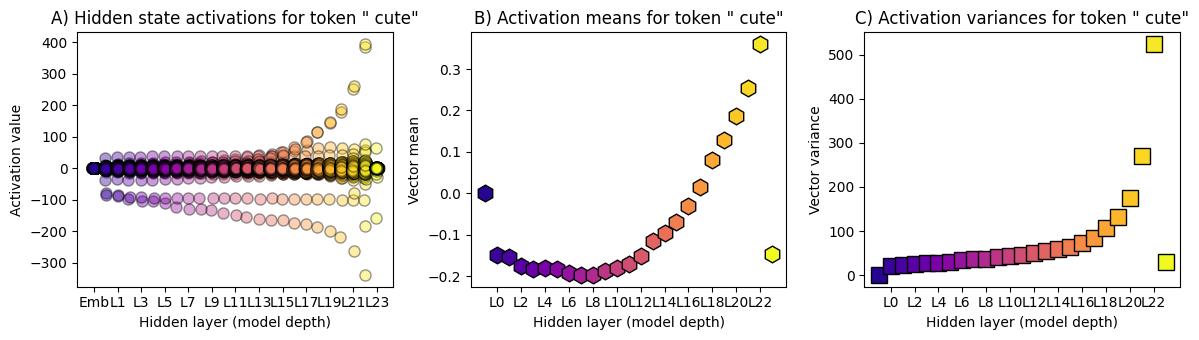

In [38]:
# all hidden-states for one token
whichToken = 8

# initialize stdev matrix
token_stds = torch.zeros((num_hidden,num_tokens))

# setup the figure
_,axs = plt.subplots(1,3,figsize=(12,3.5))

# loop over layers
for layeri in range(num_hidden):

  # extract the activations from this layer and this token
  acts = hs[layeri][0,whichToken,:]

  # plot all the activations
  axs[0].plot(np.random.normal(layeri,.05,hidden_dim),acts,'ko',markersize=8,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden),alpha=.4)

  axs[1].plot(layeri,acts.mean(),'kh',markersize=12,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden))

  # plot the variance of the activations
  axs[2].plot(layeri,acts.var(),'ks',markersize=12,
           markerfacecolor=plt.cm.plasma((layeri+1)/num_hidden))

  # standard deviation for all tokens
  token_stds[layeri,:] = hs[layeri][0,:,:].std(dim=-1)

# names of the layers, for the x-axis tick labels
layer_labels = ['Emb'] + [f'L{i}' for i in range(num_hidden-1)]

# adjust the axes
axs[0].set(xticks=range(0,num_hidden,2),xticklabels=layer_labels[::2],xlabel='Hidden layer (model depth)',
           ylabel='Activation value',title=f'A) Hidden state activations for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')

axs[1].set(xticks=range(1,num_hidden,2),xticklabels=layer_labels[1::2],xlabel='Hidden layer (model depth)',
           ylabel='Vector mean',title=f'B) Activation means for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')

axs[2].set(xticks=range(1,num_hidden,2),xticklabels=layer_labels[1::2],xlabel='Hidden layer (model depth)',
           ylabel='Vector variance',title=f'C) Activation variances for token "{tokenizer.decode(tokens['input_ids'][0,whichToken])}"')


plt.tight_layout()
plt.show()

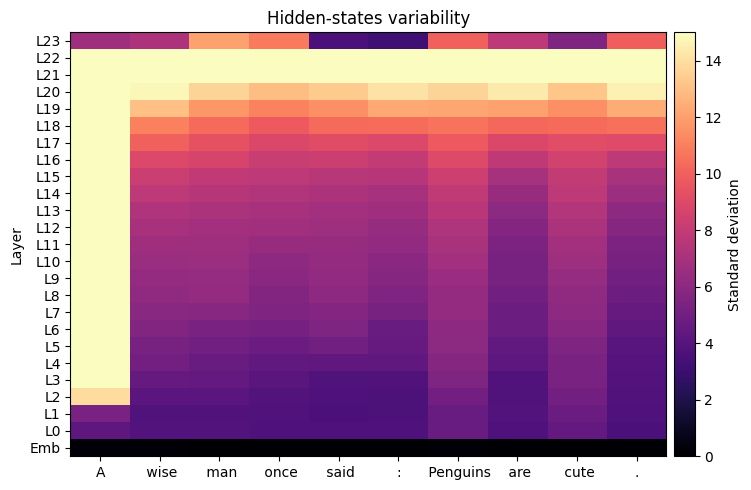

In [39]:
plt.figure(figsize=(8,5))
plt.imshow(token_stds,aspect='auto',origin='lower',
           vmin=0,vmax=15,cmap='magma')
plt.gca().set(ylabel='Layer',xticks=range(num_tokens),title='Hidden-states variability',
              xticklabels=[tokenizer.decode(t) for t in tokens['input_ids'][0]],
              yticks=range(num_hidden),yticklabels=layer_labels)
ch = plt.colorbar(pad=.01)
ch.set_label('Standard deviation')

plt.tight_layout()
plt.show()


# Part 3: Cosine similarities across layers


## Task_1:
- Identify the four token positions that are evenly spaced between the
first and the last. For each token position, extract the hidden-state
vectors across all layers. Calculate all pairwise (that is, each pair of
layers) cosine similarities for each of the four token positions, and
visualize as heatmaps as in Figure 5.4.

In [42]:
len(tokens['input_ids'][0])

10

In [41]:
np.linspace(0,len(tokens['input_ids'][0])-1,4,dtype=int)

array([0, 3, 6, 9])

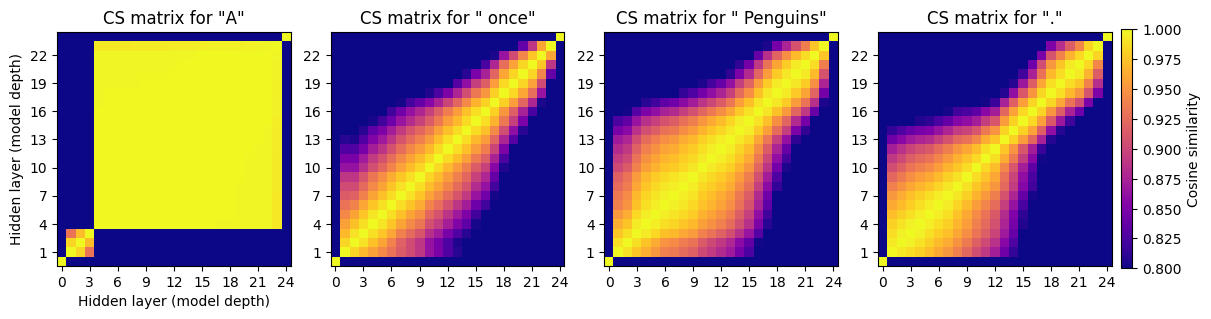

In [43]:

# pick 4 evenly spaced tokens including the first and final
tokens2analyze = np.linspace(0,len(tokens['input_ids'][0])-1,4,dtype=int)

fig,axs = plt.subplots(1,4,layout='constrained',figsize=(12,3))

cos_sims = []

# loop over selected tokens
for toki in range(len(tokens2analyze)):

  # extract the hidden-state activations from this token into a matrix
  all_hiddens = torch.zeros((num_hidden,hidden_dim))
  for layeri in range(num_hidden):
    all_hiddens[layeri,:] = hs[layeri][0,tokens2analyze[toki],:]

  # and calculate the cosine similarity matrix on all pairs of layers
  M = F.cosine_similarity(all_hiddens.unsqueeze(0),all_hiddens.unsqueeze(1),dim=-1)
  cos_sims.append(M)

  # show the matrix
  h = axs[toki].imshow(M,cmap='plasma',vmin=.8,vmax=1,origin='lower')
  axs[toki].set(xticks=range(0,num_hidden,3),yticks=range(1,num_hidden,3),
                title=f'CS matrix for "{tokenizer.decode(tokens["input_ids"][0,tokens2analyze[toki]])}"')

# adjustments
axs[0].set(xlabel='Hidden layer (model depth)',ylabel='Hidden layer (model depth)')
fig.colorbar(h,ax=axs[-1],label='Cosine similarity',pad=.02,shrink=.97)

plt.show()

## Task_2:
- Create a matrix that encodes inter-layer distances. For example,
layers 4 and 7 are three index-units apart. Visualize that matrix as
in Figure 5.5.
Make four scatter plots of distance by similarity as in Figure
5.6. For an additional challenge, use a different color for markers
from each column to visualize the layer the data values come from.